In [34]:
import calendar
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import statsmodels.api as sm
import os
import warnings
from coreforecast.scalers import boxcox, boxcox_lambda
from cycler import cycler
from functools import partial
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from statsforecast import StatsForecast
from statsforecast.models import (
    HistoricAverage,
    Naive,
    RandomWalkWithDrift,
    SeasonalNaive,
    SklearnModel
)
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from utilsforecast.evaluation import evaluate
from utilsforecast.feature_engineering import pipeline, trend
from utilsforecast.losses import rmse, mae, mape as _mape, mase, quantile_loss, mqloss
from utilsforecast.plotting import plot_series

In [3]:
warnings.filterwarnings("ignore")
np.random.seed(1)
random.seed(1)

In [4]:
def mape(df, models, id_col="Unique_id", target_col="y"):
    df_mape = _mape(df, models, id_col=id_col, target_col=target_col)
    df_mape.loc[:, df_mape.select_dtypes(include="number").columns] *= 100
    return df_mape

def quantile_score(df, models, q=0.5, id_col="Unique_id", target_col="y"):
    df_qs = quantile_loss(df, models, q=q, id_col=id_col, target_col=target_col)
    df_qs.loc[:, df_qs.select_dtypes(include="number").columns] *= 2
    return df_qs

In [6]:
gdp_df = (
    pd.read_csv("../data/fppp/global_economy.csv", parse_dates=["ds"])
    [["unique_id", "ds", "GDP", "Population"]]
    .assign(
        GDP=lambda x: x["GDP"].interpolate(),
        Population=lambda x: x["Population"].interpolate(),
        y=lambda x: x["GDP"] / x["Population"],
    )
)

In [16]:
gdp_df.head()

,unique_id,ds,GDP,Population,y
0,Afghanistan,1960-01-01,5.377778e+08,8996351.0,59.777327
1,Afghanistan,1961-01-01,5.488889e+08,9166764.0,59.878153
2,Afghanistan,1962-01-01,5.466667e+08,9345868.0,58.492874
3,Afghanistan,1963-01-01,7.511112e+08,9533954.0,78.782758
4,Afghanistan,1964-01-01,8.000000e+08,9731361.0,82.208444


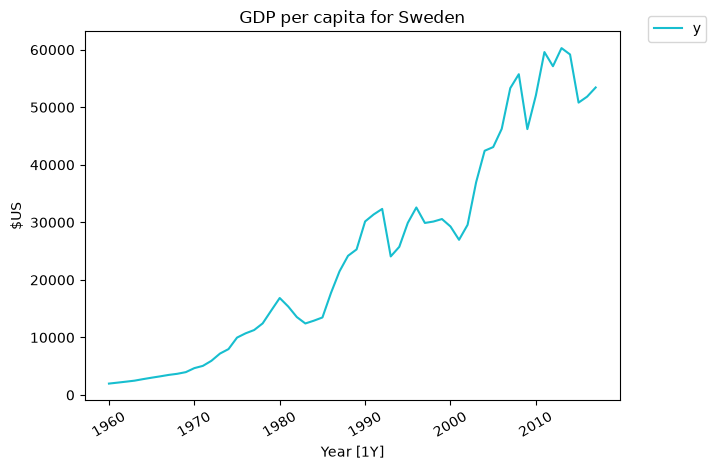

In [30]:
fig, ax = plt.subplots()
fig = plot_series(gdp_df, ids=["Sweden"], ax=ax)
ax.set(xlabel="Year [1Y]", ylabel="$US", title="GDP per capita for Sweden")
fig.tight_layout()
fig

In [31]:
sweden_df = (
    gdp_df
    .loc[lambda x: x["unique_id"] == "Sweden"]
    [["unique_id", "ds", "y"]]
)

In [35]:
train_features, valid_features = pipeline(sweden_df, features=[trend], freq="YE", h=3)
trend_model = SklearnModel(LinearRegression())
sf = StatsForecast(models=[trend_model], freq="YE")
sf.fit(df=train_features)

StatsForecast(models=[LinearRegression])

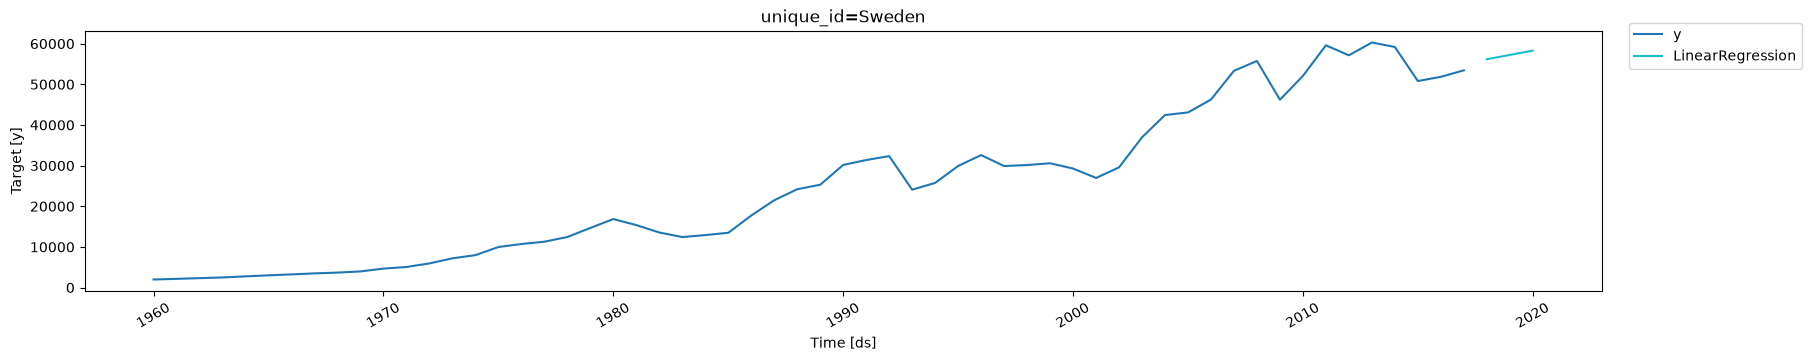

In [38]:
predictions = sf.predict(h=3, X_df=valid_features)
plot_series(sweden_df, predictions, ids=["Sweden"])

In [40]:
production_df = pd.read_csv("../data/fppp/aus_production_formatted.csv",
  parse_dates=["ds"])
bricks_df = (
  production_df.loc[lambda x: (
    (x["unique_id"] == "Bricks") & (x["ds"].between("1970", "2004-12"))
  )].dropna()
)

In [41]:
bricks_df.head()

,unique_id,ds,y
492,Bricks,1970-01-01,386.0
493,Bricks,1970-04-01,428.0
494,Bricks,1970-07-01,434.0
495,Bricks,1970-10-01,417.0
496,Bricks,1971-01-01,385.0


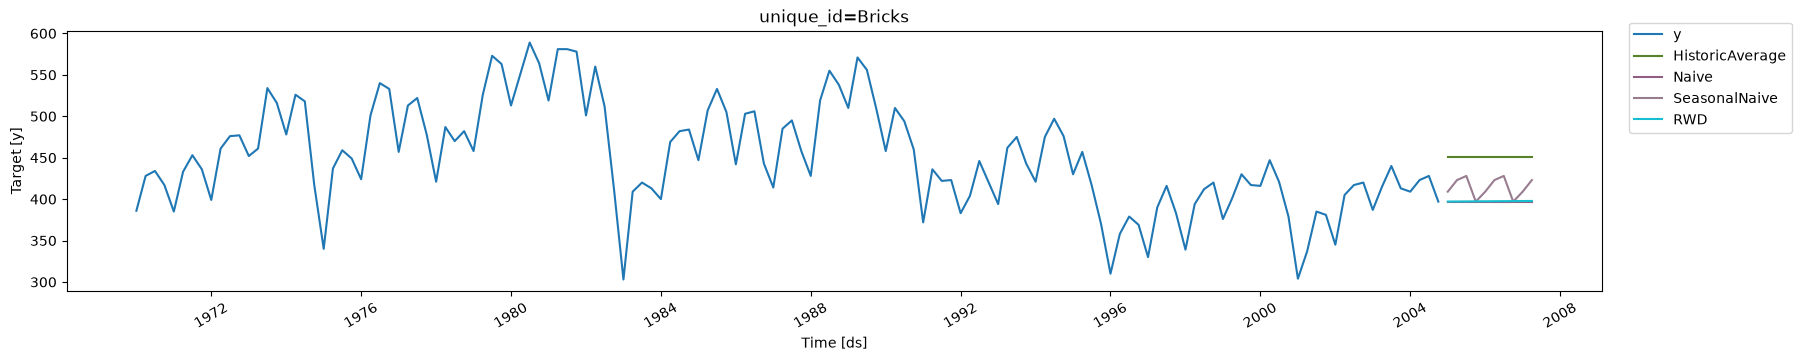

In [54]:
mean_method = HistoricAverage()
naive_method = Naive()
seasonal_naive_method = SeasonalNaive(4)
drift_method = RandomWalkWithDrift()
sf = StatsForecast(models=[mean_method, naive_method, seasonal_naive_method, drift_method], freq="QS")
sf.fit(df=bricks_df)
predictions = sf.predict(h=10)
plot_series(bricks_df, predictions)

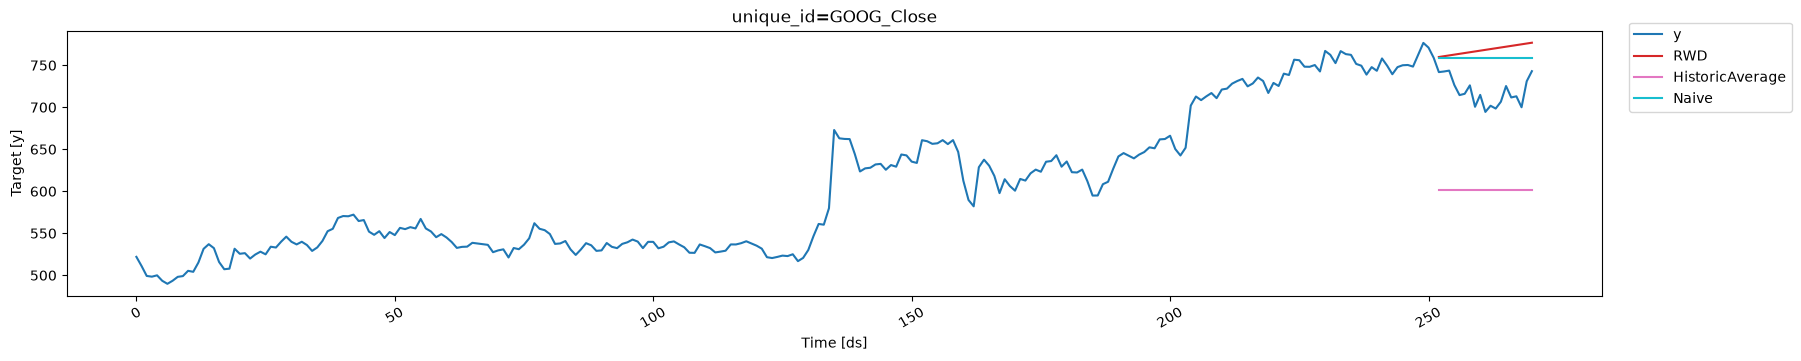

In [57]:
plt.rcParams["figure.figsize"] = (7, 4)
goog_df = (
  pd.read_csv("../data/fppp/gafa_stock.csv", parse_dates=["ds"])
  .loc[lambda x: (
    (x["unique_id"] == "GOOG_Close") & x["ds"].between("2015", "2016-01-31")
  )]
)
train = goog_df.loc[lambda x: x["ds"].dt.year == 2015].copy()
test = goog_df.loc[lambda x: x["ds"].dt.year == 2016].copy()

# Re-index based on trading days
train["ds"] = np.arange(len(train))
test["ds"] = len(train) + np.arange(len(test))

avg_method = HistoricAverage()
naive_method = Naive()
drift_method = RandomWalkWithDrift()
sf = StatsForecast(freq=1,
    models=[drift_method, avg_method, naive_method])
sf.fit(train)

fcasts = sf.predict(h=len(test)).assign(y=test["y"].to_numpy())
plot_series(train, fcasts)

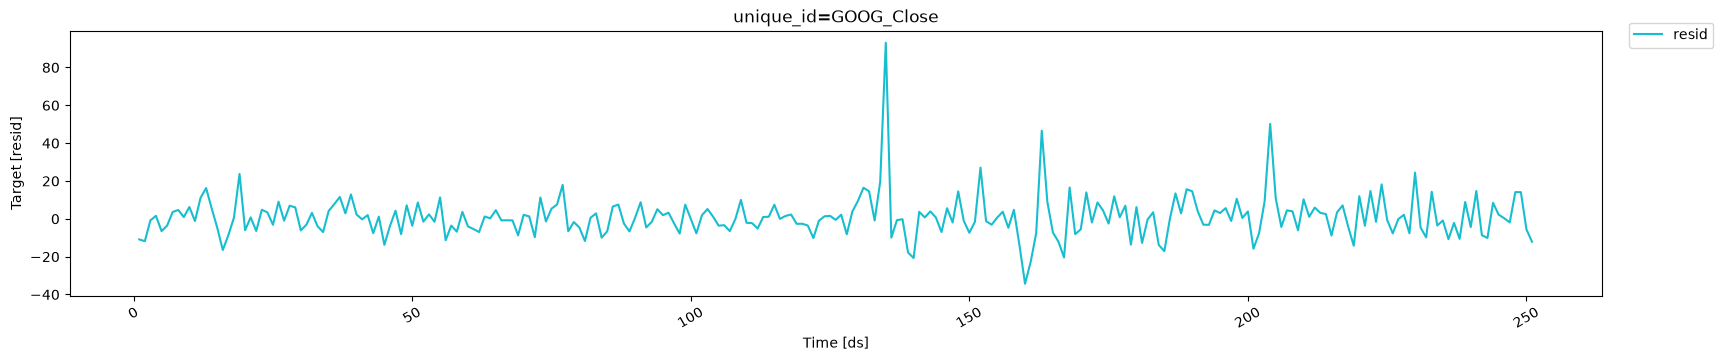

In [60]:
resid = train.assign(resid=lambda x : x["y"].diff())
plot_series(resid, target_col="resid")

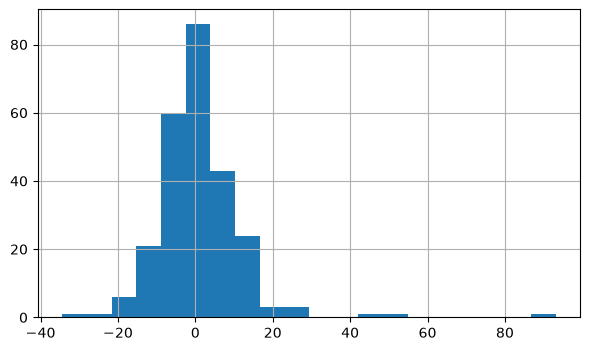

In [61]:
ax = resid["resid"].hist(bins=20)
plt.show()

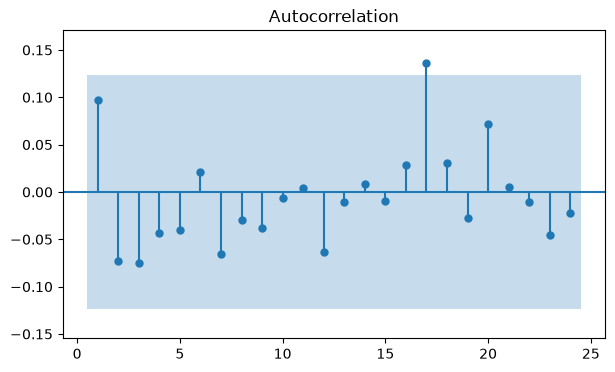

In [63]:
fig = plot_acf(resid["resid"][1:], zero=False, auto_ylims=True, bartlett_confint=False)